# Reconstruir el cálculo de energía y reciclaje

**Pregunta:** ¿Cómo explican la recirculación y las leyes calibradas el requerimiento de potencia de un producto más fino?

Nivel: 2. Requisitos previos: Nivel 1: Seguir un mineral de cobre por trituración y molienda. Tiempo de lectura: 28 minutos.



## Objetivos

Reproducir una corrida nominal con el caso declarado de OreFlow, inspeccionar las etapas de clasificación y energía, y evaluar la respuesta de la ley Bond implementada ante un cambio controlado de P80. Cada magnitud calculada procede de métodos del pipeline.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0 scikit-learn==1.5.2 ruff==0.15.18 pytest==9.1.1
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 2 sobre 01-comminution, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importar herramientas de análisis y registrar sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))
legend_style = dict(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow, licencia MIT. El catálogo aporta mineral, triturador, molino, clasificador y operación nominal del pórfido blando. Las constantes y extremos de referencia provienen de engine/data/constants.json. Salidas y distribuciones de tamaño se calculan aquí, sin cargar una traza guardada. No se introduce distribución medida, campaña energética ni otro conjunto externo. Fuente: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El requerimiento estándar de Bond es $W_B=W_i(10/\sqrt{P_{80}}-10/\sqrt{F_{80}})$ en kWh/t (GMG01-MP-2021, ec. 3). OreFlow reporta por separado la energía neta de molienda. El clasificador actúa sobre cada clase de tamaño y resuelve el bucle de reciclaje; el underflow no es alimentación fresca. `energy_report` y `law_curves` son implementaciones del pipeline, no copias en el notebook.

Volver a ejecutar el motor de producción para que esta lección sea ejecutable de forma independiente. Inspeccionar la potencia calculada, el corte del clasificador, la carga circulante y la finura.

In [2]:
# Volver a ejecutar el motor de producción para que esta lección sea ejecutable de forma
# independiente.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next((item for item in CASES if item.id == "copper_porphyry_soft"))
result = simulate(case.ore, case.plant, case.nominal)
grind = result.grinding
print("potencia del molino (kW):", round(grind.power_kw, 1))
print("potencia requerida (kW):", round(grind.required_power_kw, 1))
print("corte del clasificador (µm):", round(grind.cut_um, 1))
print("carga circulante (%):", round(100 * grind.circulating_load, 1))
print("limitado por potencia:", grind.power_limited)


potencia del molino (kW): 6456.5
potencia requerida (kW): 6456.5
corte del clasificador (µm): 183.9
carga circulante (%): 250.0
limitado por potencia: False


Inspeccionar valores de partición para clases de tamaño seleccionadas. La partición es la fracción de una clase que va al underflow; no es la fracción del flujo total que se recicla.

,size_um,underflow_share
0,137550.606481,NaN
1,34387.651620,NaN
2,7229.113244,1.000000
3,1519.733853,1.000000
4,319.484687,0.912833
5,67.163382,0.347523
6,14.119362,0.287011
7,2.968230,0.284220


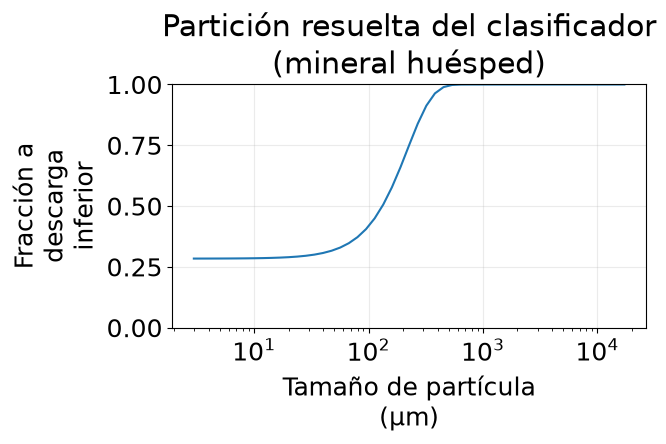

In [3]:
# Inspeccionar valores de partición para clases de tamaño seleccionadas.
plt.rcParams.update({"font.size": 18, "axes.titlepad": 8})
size = np.asarray(result.curves["size_um"])
partition = np.asarray([v if v is not None else np.nan for v in grind.partition["host"]])
selected = np.linspace(0, len(size) - 1, 8, dtype=int)
display(pd.DataFrame({"size_um": size[selected], "underflow_share": partition[selected]}))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(size, partition)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set(
    xlabel="Tamaño de partícula\n(µm)",
    ylabel="Fracción a\ndescarga\ninferior",
    title="Partición resuelta del clasificador\n(mineral huésped)",
)
ax.grid(True, alpha=0.25)
fig.subplots_adjust(left=0.22, right=0.96, bottom=0.23, top=0.87)
ax.locator_params(axis="x", numticks=4)
ax.tick_params(axis="x", which="minor", labelbottom=False)


La partición separa partículas que van a descarga inferior y rebose. Su eje vertical es una fracción, no porcentaje acumulado de tamaño. El panel energético usa extremos comunes para comparar hipótesis de reducción. Ni una partición marcada ni la coincidencia de fórmulas establece calibración de planta: recirculación, desvío y potencia requerida deben ser coherentes con la red resuelta.

Llamar a la función de reporte energético de OreFlow con F80/P80 y la energía neta calculada. El reporte mantiene separados el requerimiento de Bond y las leyes alternativas de comparación.

In [4]:
# Llamar a la función de reporte energético de OreFlow con F80/P80 y la energía neta calculada.
from pipeline.engine.energy import energy_report

energy = energy_report(
    case.nominal.work_index_kwh_t,
    case.ore.crushing_work_index_kwh_t,
    result.metrics["crusher_feed_f80_um"],
    result.metrics["crusher_p80_um"],
    grind.specific_energy_kwh_t,
    grind.feed_f80_um,
    grind.p80_um,
)
display(pd.Series(energy, name="kWh/t o adimensional").to_frame())


,kWh/t o adimensional
specific_energy_crushing_kwh_t,0.825221
specific_energy_grinding_kwh_t,8.967354
specific_energy_total_kwh_t,9.792575
bond_energy_kwh_t,7.782543
operating_work_index_kwh_t,12.674635
bond_efficiency_ratio,0.867875
energy_rittinger_kwh_t,7.858905
energy_kick_kwh_t,7.558261


Varía únicamente el tamaño de producto en la ecuación de Bond, manteniendo fijo el índice de trabajo y F80 de alimentación. Es un análisis de sensibilidad con la función implementada en OreFlow, no una optimización de planta.

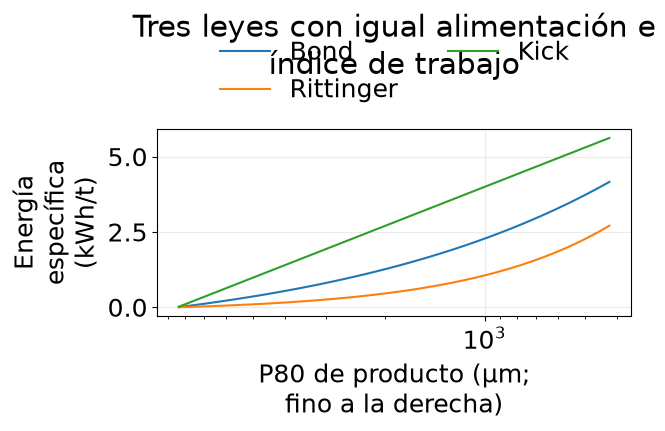

In [5]:
# Varía únicamente el tamaño de producto en la ecuación de Bond, manteniendo fijo el índice de
# trabajo y F80 de alimentación.
plt.rcParams.update({"font.size": 18, "axes.titlepad": 40})
from pipeline.engine.energy import law_curves

f80 = max(grind.feed_f80_um, 2 * grind.p80_um)
p80_values = np.geomspace(max(70, f80 / 20), f80 / 1.01, 40)
laws = law_curves(case.nominal.work_index_kwh_t, f80, p80_values)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for name in ("bond", "rittinger", "kick"):
    ax.plot(laws["p80_um"], laws[name], label=name.title())
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(
    xlabel="P80 de producto (µm;\nfino a la derecha)",
    ylabel="Energía\nespecífica\n(kWh/t)",
    title="Tres leyes con igual alimentación e\níndice de trabajo",
)
ax.grid(True, alpha=0.25)
ax.legend(ncol=2, **legend_style)
fig.subplots_adjust(left=0.22, right=0.96, bottom=0.23, top=0.72)
ax.locator_params(axis="x", numticks=4)
ax.tick_params(axis="x", which="minor", labelbottom=False)


Las curvas de energía absoluta mantienen F80 de alimentación al molino e índice de trabajo fijos mientras varía el producto. Su separación representa hipótesis alternativas en kWh/t, no componentes aditivos de potencia. A diferencia de la partición, no muestran fracciones de flujo. Comparar con P80 alcanzado y potencia requerida permite evaluar si el requerimiento corresponde a un estado realizable.

La partición anterior tiene sentido junto a la alimentación resuelta al molino. Restablecer el nominal y obtener su F80 antes de calcular trabajo. Así la explicación energética usa el mismo circuito balanceado que la tabla de partición. Una fracción alta a descarga inferior recircula material y cambia carga interna, pero no multiplica la base fresca de energía específica. Separar esas bases al pasar de partición a potencia.

In [6]:
# Resolver el circuito nominal antes de evaluar hipótesis alternativas de energía.
from pipeline.cases.catalog import CASE_BY_ID
from pipeline.engine.circuit import simulate
from pipeline.engine.energy import law_curves

case = CASE_BY_ID["copper_porphyry_soft"]
nominal = simulate(case.ore, case.plant, case.nominal)
f80 = nominal.grinding.feed_f80_um
wi = case.nominal.work_index_kwh_t
print("F80 alcanzado del molino (µm):", round(f80, 2))


F80 alcanzado del molino (µm): 8417.93


Obtener una tabla de tres leyes con el producto alcanzado. Aquí importa la disciplina contable: no sumar los requerimientos diagnósticos Rittinger o Kick a Bond ni a la energía neta simulada. Son hipótesis competidoras con calibración común. La tabla permite revisar unidades y extremos antes de afinar el objetivo. Inferir un índice operativo desde energía neta responde otra pregunta que predecir energía con el índice del mineral.

In [7]:
# Calcular el trabajo calibrado al tamaño de producto alcanzado.
at_product = law_curves(wi, f80, np.array([nominal.grinding.p80_um]))
display(pd.DataFrame(at_product).round(3))


,p80_um,bond,rittinger,kick
0,150.0,7.783,7.859,7.558


Solicitar molienda más fina e inspeccionar la demanda que devuelve el motor completo. La recirculación se resuelve de nuevo; la respuesta incluye cambios de red además de la relación energía-tamaño. No alcanzar el objetivo integra la respuesta. Revisar cercanía entre tamaños y si la potencia requerida supera la instalación antes de interpretar una mejora de recuperación como opción operativa disponible.

In [8]:
# Solicitar al motor un producto más fino manteniendo fijos alimentación fresca y mineral.
fine_point = case.nominal.with_values(target_p80_um=case.nominal.target_p80_um * 0.8)
fine = simulate(case.ore, case.plant, fine_point)
print("P80 solicitado (µm):", fine_point.target_p80_um)
print("P80 alcanzado (µm):", round(fine.grinding.p80_um, 3))
print("Potencia requerida (kW):", round(fine.grinding.required_power_kw, 3))


P80 solicitado (µm): 120.0
P80 alcanzado (µm): 124.273
Potencia requerida (kW): 7433.457


Muévete en sentido contrario con un objetivo más grueso. Comparar ambos lados evita presentar un experimento unidireccional como tendencia general. Engrosar puede liberar la restricción de potencia y reducir liberación y recuperación. La recuperación impresa complementa la demanda, no la reemplaza. No se asigna economía a las salidas ni se afirma que el nominal sea económicamente óptimo.

In [9]:
# Repetir con un objetivo más grueso para rodear el punto nominal.
coarse_point = case.nominal.with_values(target_p80_um=case.nominal.target_p80_um * 1.2)
coarse = simulate(case.ore, case.plant, coarse_point)
print("Recuperación con molienda gruesa (%):", round(coarse.metrics["recovery_pct"], 3))
print("Potencia con molienda gruesa (kW):", round(coarse.grinding.required_power_kw, 3))


Recuperación con molienda gruesa (%): 88.256
Potencia con molienda gruesa (kW): 5755.99


Generar un dominio común de tamaños para las leyes. El límite inferior permanece positivo y el superior por debajo de la alimentación: cada cociente representa reducción. Calcular las tres leyes mediante el pipeline y divide las alternativas diagnósticas por Bond. Los cocientes destacan formas, mientras la tabla anterior conserva kWh/t absolutos. Ambas vistas evitan considerar importante una diferencia relativa pequeña con demanda casi nula.

In [10]:
# Evaluar las tres leyes en el mismo barrido logarítmico de producto.
products = np.geomspace(max(50.0, f80 / 30), f80 / 1.1, 40)
sweep = law_curves(wi, f80, products)
ratio = {
    name: np.asarray(sweep[name]) / np.asarray(sweep["bond"]) for name in ("rittinger", "kick")
}
print("Máximo Rittinger / Bond:", round(float(max(ratio["rittinger"])), 3))


Máximo Rittinger / Bond: 0.77


Dibujar la comparación normalizada con tamaño logarítmico y referencia Bond unitaria. El panel pregunta cómo divergen las hipótesis al pedir un producto más fino. Mantiene fijo el índice de trabajo, sin mezclar dureza y tamaño. Usar los estados nominal, fino y grueso como anclas físicas; las curvas continuas evalúan ecuaciones, no representan resoluciones adicionales del circuito.

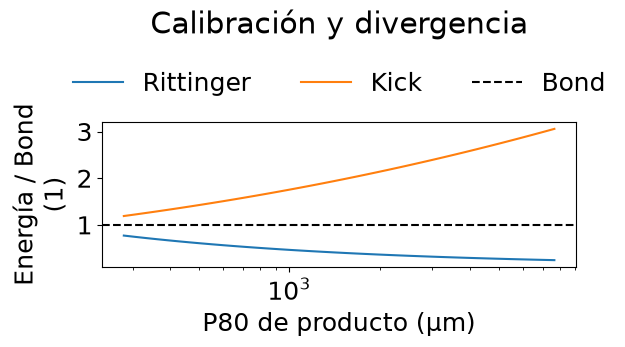

In [11]:
# Graficar la divergencia relativa de las leyes para distinguir coincidencia de calibración y forma
# de cada hipótesis de reducción..
plt.rcParams.update({"font.size": 18, "axes.titlepad": 64})
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for name, values in ratio.items():
    ax.plot(products, values, label=name.title())
ax.axhline(1.0, color="black", linestyle="--", label="Bond")
ax.set(
    xscale="log",
    xlabel="P80 de producto (µm)",
    ylabel="Energía / Bond\n(1)",
    title="Calibración y divergencia",
)
ax.legend(ncol=3, **legend_style)
fig.subplots_adjust(left=0.22, right=0.96, bottom=0.23, top=0.61)
ax.locator_params(axis="x", numticks=4)
ax.tick_params(axis="x", which="minor", labelbottom=False)


Las curvas relativas muestran dónde difieren más las hipótesis inversa y logarítmica respecto de raíz cuadrada inversa. Su intersección está condicionada por calibración y no certifica un modelo para otro mineral. Un cociente cercano a uno puede coexistir con un objetivo inalcanzable por falta de potencia. Integrar figura, P80 alcanzado, potencia y partición para explicar el cálculo completo, sin escoger una ecuación solo por cercanía visual a Bond.

## Resultados

**Respuesta:** El circuito fino requiere <!-- result:Potencia fina requerida (kW) -->7433.457<!-- /result --> kW y alcanza <!-- result:P80 fino alcanzado (µm) -->124.273<!-- /result --> µm tras resolver clasificación y recirculación. Con extremos nominales los trabajos diagnósticos son Bond <!-- result:Trabajo Bond (kWh/t) -->7.783<!-- /result -->, Rittinger <!-- result:Trabajo Rittinger (kWh/t) -->7.859<!-- /result --> y Kick <!-- result:Trabajo Kick (kWh/t) -->7.558<!-- /result --> kWh/t. Son requerimientos alternativos; partición y tamaño alcanzado explican la respuesta física del circuito.

Resumir demanda de potencia fina y trabajos nominales alternativos sobre la base de alimentación declarada al molino.

In [12]:
# Resumir las salidas calculadas que sostienen la interpretación de esta lección.
answer_values = {
    "P80 nominal (µm)": nominal.grinding.p80_um,
    "P80 fino solicitado (µm)": fine_point.target_p80_um,
    "P80 fino alcanzado (µm)": fine.grinding.p80_um,
    "Potencia fina requerida (kW)": fine.grinding.required_power_kw,
    "Trabajo Bond (kWh/t)": at_product["bond"][0],
    "Trabajo Rittinger (kWh/t)": at_product["rittinger"][0],
    "Trabajo Kick (kWh/t)": at_product["kick"][0],
}
answer_values = {label: round(float(number), 3) for label, number in answer_values.items()}
print(json.dumps(answer_values, ensure_ascii=False))


{"P80 nominal (µm)": 150.0, "P80 fino solicitado (µm)": 120.0, "P80 fino alcanzado (µm)": 124.273, "Potencia fina requerida (kW)": 7433.457, "Trabajo Bond (kWh/t)": 7.783, "Trabajo Rittinger (kWh/t)": 7.859, "Trabajo Kick (kWh/t)": 7.558}


## Resumen

La partición del clasificador, la carga circulante y las salidas de energía proceden del mismo motor. El circuito es estacionario; estas ecuaciones no representan la fractura en tiempo real, y la planta nominal es un escenario de autoría propia.

## Referencias

- https://www.globalminingguidelines.org/guidelines/bond-efficiency/
- https://doi.org/10.1016/0301-7516(80)90034-4
- https://doi.org/10.1016/0301-7516(80)90034-4